11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.2050
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.1416
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.1121
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0954
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.0857
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


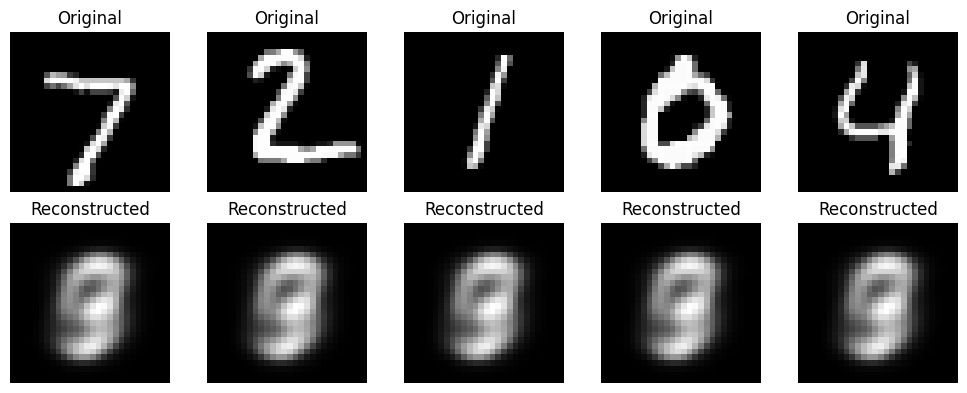

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.regularizers import l1

(x_train, _), (x_test, _) = mnist.load_data()

x_train = x_train.reshape(-1, 784) / 255
x_test = x_test.reshape(-1, 784) / 255

model = Sequential([
    Input(shape=(784,)),
    Dense(64, activation="relu", activity_regularizer=l1(0.001)),
    Dense(784, activation="sigmoid")
])

model.compile(optimizer="adam", loss="mse")
model.fit(x_train, x_train, epochs=5, batch_size=128)

pred = model.predict(x_test[:5])

plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 5, i+6)
    plt.imshow(pred[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0519
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0294
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 0.0265
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0249
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0237
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0230
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0224
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0220
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0216
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0213
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0193
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


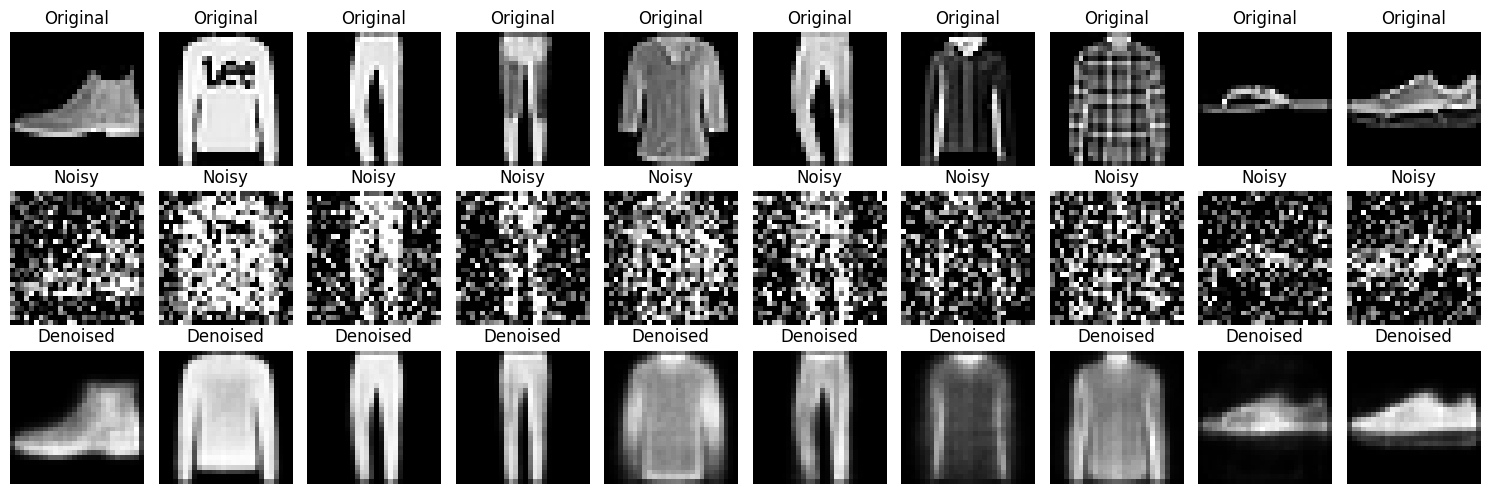

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

(x_train, _), (x_test, _) = fashion_mnist.load_data()

x_train = x_train.reshape(-1, 784) / 255.0
x_test = x_test.reshape(-1, 784) / 255.0
def add_noise(x):
    noise = np.random.normal(0, 0.5, x.shape)
    return np.clip(x + noise, 0, 1)

train_noisy = add_noise(x_train)
test_noisy = add_noise(x_test)

model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(128, activation="relu"),
    Dense(784, activation="sigmoid")
])

model.compile(optimizer="adam", loss="mse")

model.fit(train_noisy, x_train, epochs=10, batch_size=256)

model.evaluate(test_noisy, x_test)

pred = model.predict(test_noisy[:10])

plt.figure(figsize=(15, 5))

for i in range(10):
    plt.subplot(3, 10, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(3, 10, i+11)
    plt.imshow(test_noisy[i].reshape(28, 28), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

    plt.subplot(3, 10, i+21)
    plt.imshow(pred[i].reshape(28, 28), cmap="gray")
    plt.title("Denoised")
    plt.axis("off")

plt.tight_layout()
plt.show()